In [52]:
# Exploratory Data Analysis for the MMM Dataset
# Sales volume is in kg; price variables are GBP per kg.
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

df=pd.read_csv("MMM_Dataset.csv")
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").reset_index(drop=True)

SOURCE_NCOLS = df.shape[1]

df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").reset_index(drop=True)

print(f"Loaded {len(data)} weekly records, {data.shape[1]} source columns")
print(f"Period: {data['Date'].min():%d %b %Y} to {data['Date'].max():%d %b %Y}")
print("Source:", DATA_PATH)


Loaded 169 weekly records, 47 source columns
Period: 03 Apr 2023 to 22 Jun 2026
Source: MMM_Dataset.csv


## 1. Quick exploratory analysis



In [53]:
data.shape

(169, 47)

In [54]:
data.columns

Index(['Date', 'Volume_Sales', 'Value_Sales', 'Promotion_Volume_Sales',
       'Promotion_Value_Sales', 'Avg_Price', 'Base_Avg_Price',
       'Promotion_Avg_Price', 'ACV_Weighted_Distribution_max',
       'ACV_Weighted_Distribution_wtd',
       'Promotion_ACV_Weighted_Distribution_max',
       'Promotion_ACV_Weighted_Distribution_wtd', 'Comp_Brand1_Volume_Sales',
       'Comp_Brand1_Value_Sales', 'Comp_Brand1_Promotion_Volume_Sales',
       'Comp_Brand1_Promotion_Value_Sales', 'Comp_Brand1_Avg_Price',
       'Comp_Brand1_Base_Avg_Price', 'Comp_Brand1_Promotion_Avg_Price',
       'Comp_Brand1_ACV_Weighted_Distribution_max',
       'Comp_Brand1_ACV_Weighted_Distribution_wtd',
       'Comp_Brand1_Promotion_ACV_Weighted_Distribution_max',
       'Comp_Brand1_Promotion_ACV_Weighted_Distribution_wtd',
       'Comp_Brand2_Volume_Sales', 'Comp_Brand2_Value_Sales',
       'Comp_Brand2_Promotion_Volume_Sales',
       'Comp_Brand2_Promotion_Value_Sales', 'Comp_Brand2_Avg_Price',
       'Comp_Bran

In [55]:
display(data.head(8))
print("Missing values:", int(data.isna().sum().sum()))
print("Duplicated weeks:", int(data["Date"].duplicated().sum()))
print("Volume sales (kg):")
display(data["Volume_Sales"].describe().round(1))


,Date,Volume_Sales,Value_Sales,Promotion_Volume_Sales,Promotion_Value_Sales,Avg_Price,Base_Avg_Price,Promotion_Avg_Price,ACV_Weighted_Distribution_max,ACV_Weighted_Distribution_wtd,...,weather_max_temp,weather_min_temp,weather_rainfall,Md_OnlineVideo_Spends,Md_Social_Spends,Md_TV_Spends,Md_Digital_Partner_Spends,Md_OOH_Spends,Md_RDM_Spends,Md_Search_Spends
0,2023-04-03,3724577.46,2349481.88,868645.08,265563.30,0.6308,0.6794,0.3057,55.4400,41.5010,...,8.5587,2.2637,27.8443,18606.96,11786.51,138209.87,0.00,0.0,0.00,0.0
1,2023-04-10,3601118.70,2303558.68,814452.04,327955.91,0.6397,0.6751,0.4027,55.8655,42.7810,...,15.2387,2.6202,10.6752,0.00,0.00,0.00,0.00,0.0,0.00,0.0
2,2023-04-17,3830409.74,2487048.23,995888.83,358404.62,0.6493,0.6925,0.3599,55.4644,42.3396,...,13.7920,5.5119,9.2333,0.00,0.00,0.00,0.00,0.0,0.00,0.0
3,2023-04-24,3526635.91,2308437.16,839874.10,423656.40,0.6546,0.6770,0.5044,52.5452,38.3248,...,18.6881,6.8353,7.1772,0.00,0.00,0.00,0.00,0.0,0.00,0.0
4,2023-05-01,3709010.95,2441181.96,846686.24,346582.24,0.6582,0.6954,0.4093,55.5119,44.9390,...,17.7516,5.4284,6.9804,6207.66,0.00,0.00,0.00,0.0,303.16,0.0
5,2023-05-08,4310223.27,2863792.70,913460.69,411643.46,0.6644,0.6964,0.4506,53.1743,41.4787,...,20.5781,7.8134,9.8460,0.00,19421.20,198982.56,0.00,0.0,57.60,0.0
6,2023-05-15,4229093.14,2862015.33,1042878.83,493245.15,0.6767,0.7072,0.4730,56.1217,42.6946,...,18.5274,6.2986,3.0409,0.00,0.00,0.00,26718.51,0.0,0.00,0.0
7,2023-05-22,3960800.03,2767131.00,895337.49,387525.51,0.6986,0.7383,0.4328,53.0245,40.5782,...,17.9954,5.5040,12.2247,0.00,0.00,0.00,0.00,0.0,0.00,0.0


Missing values: 0
Duplicated weeks: 0
Volume sales (kg):


,Volume_Sales
count,169.0
mean,3302049.8
std,658177.7
min,2078842.4
25%,2718412.8
50%,3361617.6
75%,3889581.7
max,4678307.4


In [56]:
# Updated fields for the latest 169-week dataset
TARGET = "Volume_Sales"  # kilograms, not units
DATE_COL = "Date"
MEDIA_COLS = [
    "Md_OnlineVideo_Spends",
    "Md_Social_Spends",
    "Md_TV_Spends",
    "Md_Digital_Partner_Spends",
    "Md_OOH_Spends",
    "Md_RDM_Spends",
    "Md_Search_Spends",
]
media_features = MEDIA_COLS  # consistent with existing plotting cells
media_labels = {c: c.removeprefix("Md_").removesuffix("_Spends").replace("_", " ") for c in MEDIA_COLS}

price_features = ["Base_Avg_Price", "Promotion_Avg_Price"]
distribution_features = [
    "ACV_Weighted_Distribution_wtd",
    "Promotion_ACV_Weighted_Distribution_wtd",
]
competitor_features = [
    "Comp_Brand1_Base_Avg_Price",
    "Comp_Brand1_Promotion_Avg_Price",
    "Comp_Brand2_Base_Avg_Price",
    "Comp_Brand2_Promotion_Avg_Price",
    "Comp_Brand1_Md_Spends",
    "Comp_Brand2_Md_Spends",
]
weather_features = ["weather_average_temp", "weather_rainfall"]

selected_features = (
    [DATE_COL, TARGET]
    + MEDIA_COLS
    + price_features
    + distribution_features
    + competitor_features
    + weather_features
)


In [57]:
mmm_df = data[selected_features].copy()
print("Selected features shape:", mmm_df.shape)
display(mmm_df.head(5))


Selected features shape: (169, 21)


,Date,Volume_Sales,Md_OnlineVideo_Spends,Md_Social_Spends,Md_TV_Spends,Md_Digital_Partner_Spends,Md_OOH_Spends,Md_RDM_Spends,Md_Search_Spends,Base_Avg_Price,...,ACV_Weighted_Distribution_wtd,Promotion_ACV_Weighted_Distribution_wtd,Comp_Brand1_Base_Avg_Price,Comp_Brand1_Promotion_Avg_Price,Comp_Brand2_Base_Avg_Price,Comp_Brand2_Promotion_Avg_Price,Comp_Brand1_Md_Spends,Comp_Brand2_Md_Spends,weather_average_temp,weather_rainfall
0,2023-04-03,3724577.46,18606.96,11786.51,138209.87,0.0,0.0,0.00,0.0,0.6794,...,41.5010,12.2787,1.1950,0.9683,0.6378,0.4608,0.0,0.0,5.3123,27.8443
1,2023-04-10,3601118.70,0.00,0.00,0.00,0.0,0.0,0.00,0.0,0.6751,...,42.7810,9.7712,0.9404,0.6509,0.6506,0.4584,0.0,0.0,7.8960,10.6752
2,2023-04-17,3830409.74,0.00,0.00,0.00,0.0,0.0,0.00,0.0,0.6925,...,42.3396,15.5019,1.2369,0.8597,0.6607,0.5004,0.0,50968.1,9.6413,9.2333
3,2023-04-24,3526635.91,0.00,0.00,0.00,0.0,0.0,0.00,0.0,0.6770,...,38.3248,11.5827,1.1300,0.8164,0.6214,0.4433,0.0,0.0,12.5318,7.1772
4,2023-05-01,3709010.95,6207.66,0.00,0.00,0.0,0.0,303.16,0.0,0.6954,...,44.9390,12.9381,1.1654,0.7708,0.6863,0.5348,0.0,0.0,11.3274,6.9804


## 2. Media activity and weekly seasonality


In [58]:
# Summarise campaign sparsity and media spend by channel
media_summary = []
total_media_spend = mmm_df[MEDIA_COLS].sum().sum()
for col in MEDIA_COLS:
    active = mmm_df[col].gt(0)
    media_summary.append({
        "Channel": media_labels[col],
        "Active_Weeks": int(active.sum()),
        "Zero_Weeks_%": 100.0 * (1.0 - active.mean()),
        "Total_Spend": float(mmm_df[col].sum()),
        "Spend_Share_%": 100.0 * mmm_df[col].sum() / total_media_spend if total_media_spend else np.nan,
    })
media_summary = pd.DataFrame(media_summary).sort_values("Total_Spend", ascending=False)
display(media_summary.style.format({
    "Zero_Weeks_%": "{:.1f}%",
    "Total_Spend": "£{:,.0f}",
    "Spend_Share_%": "{:.1f}%",
}))


,Channel,Active_Weeks,Zero_Weeks_%,Total_Spend,Spend_Share_%
2,TV,5,97.0%,"£879,766",24.0%
0,OnlineVideo,23,86.4%,"£872,879",23.8%
1,Social,31,81.7%,"£799,684",21.8%
3,Digital Partner,15,91.1%,"£669,543",18.3%
4,OOH,7,95.9%,"£418,998",11.4%
6,Search,12,92.9%,"£15,466",0.4%
5,RDM,49,71.0%,"£11,193",0.3%


In [59]:
from statsmodels.tsa.seasonal import seasonal_decompose

def trend_and_seasonality(df, target_col, period=52):
    """Decompose weekly sales into descriptive trend and annual seasonal components.

    These are exploratory summaries; do not use them as forecasting features
    without guarding against leakage from future weeks.
    """
    if len(df) < 2 * period:
        raise ValueError(f"Seasonal decomposition requires at least {2 * period} weeks")
    weekly = df.set_index("Date")[target_col].asfreq("W-MON")
    if weekly.isna().any():
        raise ValueError("Missing weekly sales observations")
    fitted = seasonal_decompose(
        weekly, model="additive", period=period, extrapolate_trend="freq"
    )
    out = df.copy()
    out[f"trend_{target_col}"] = fitted.trend.to_numpy()
    out[f"seasonality_{target_col}"] = fitted.seasonal.to_numpy()
    return out


In [60]:
from statsmodels.tsa.seasonal import seasonal_decompose

def trend_and_seasonality(df,parameter):
    '''
    df: refers to the dataframe containing data
    parameter referes to the parameter for which you want to calculate trend
    '''
    df.index.freq='W' ## TO make sure that freq is correct
    df['trend_'+parameter]=seasonal_decompose(df[parameter], model='additive',extrapolate_trend=1,two_sided=False).trend
    df['seasonality_'+parameter]=seasonal_decompose(df[parameter] ,model='additive').seasonal

    return df

In [61]:
mmm_df=trend_and_seasonality(mmm_df,'Volume_Sales')

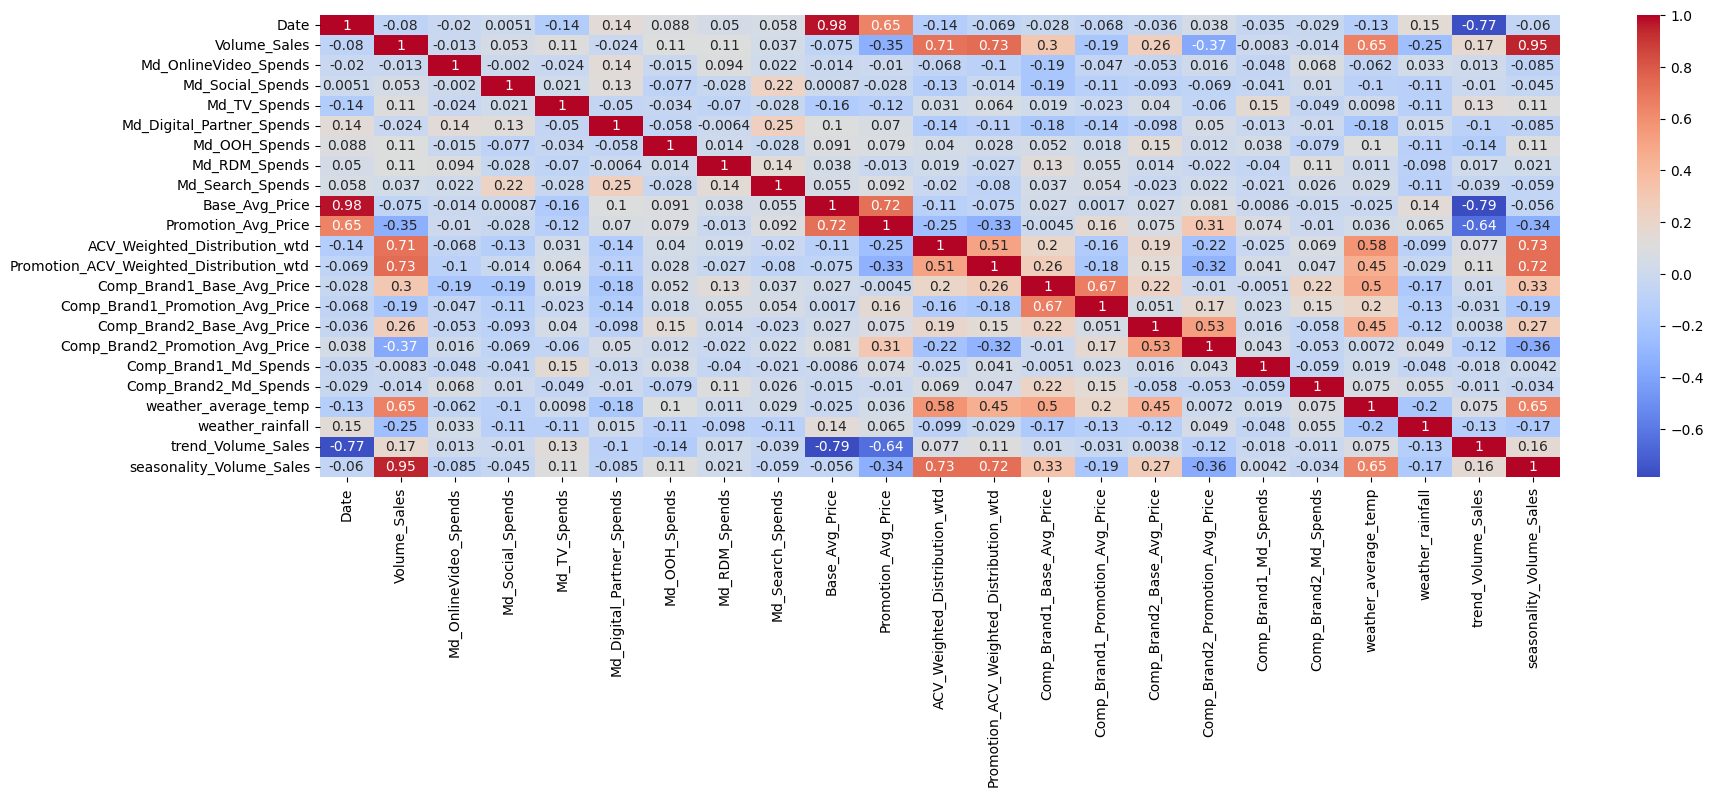

In [62]:
import seaborn as sns
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(20,6))
results=mmm_df.corr()
p1 = sns.heatmap(results,annot=True, cmap="coolwarm")

In [63]:
R1=results['Volume_Sales']
R1

,Volume_Sales
Date,-0.079947
Volume_Sales,1.000000
Md_OnlineVideo_Spends,-0.012922
Md_Social_Spends,0.052932
Md_TV_Spends,0.110417
Md_Digital_Partner_Spends,-0.023751
Md_OOH_Spends,0.105002
Md_RDM_Spends,0.105120
Md_Search_Spends,0.036523
Base_Avg_Price,-0.074557


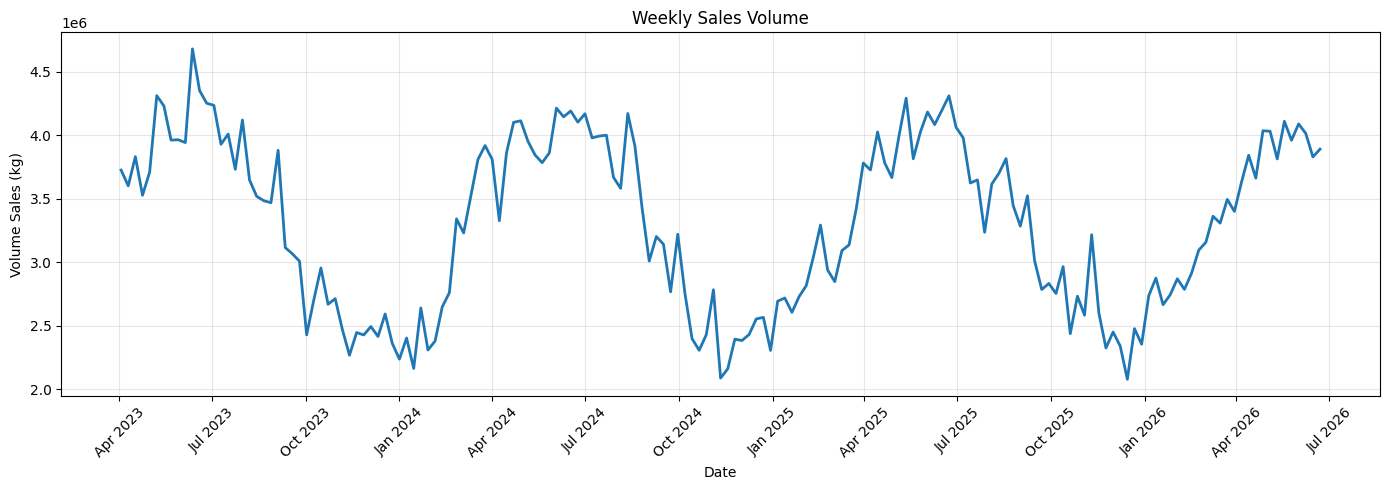

In [64]:
# weekly sales (kg)
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(data["Date"], data[TARGET], linewidth=2)
ax.set(title="Weekly Sales Volume", xlabel="Date", ylabel="Volume Sales (kg)")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.tick_params(axis="x", rotation=45)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


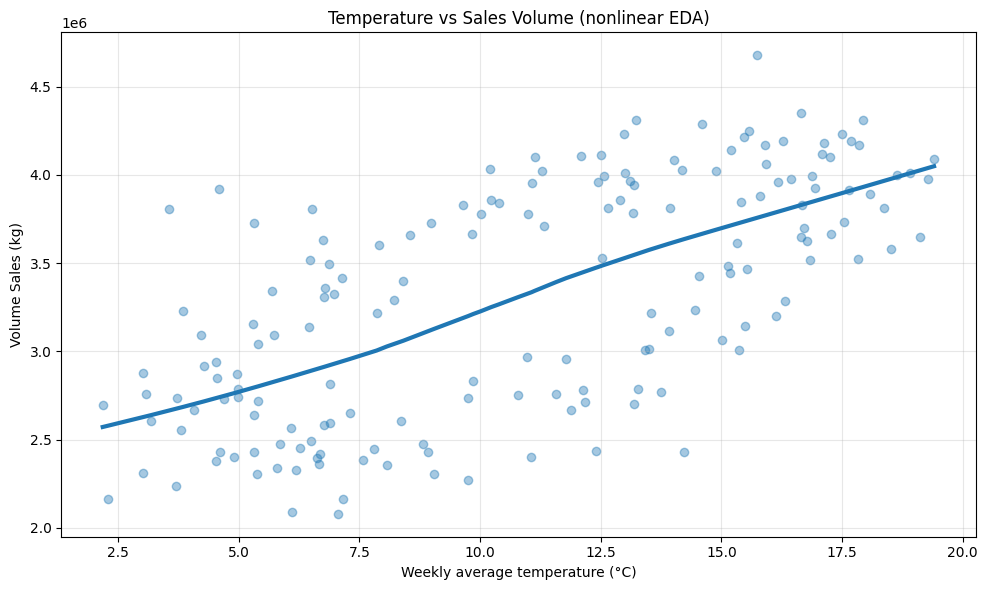

In [65]:
# Weather relationship: temperature vs. sales
fig, ax = plt.subplots(figsize=(10, 6))
sns.regplot(
    data=mmm_df, x="weather_average_temp", y=TARGET,
    lowess=True, scatter_kws={"alpha": 0.4}, line_kws={"linewidth": 3}, ax=ax
)
ax.set(title="Temperature vs Sales Volume (nonlinear EDA)",
       xlabel="Weekly average temperature (°C)", ylabel="Volume Sales (kg)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


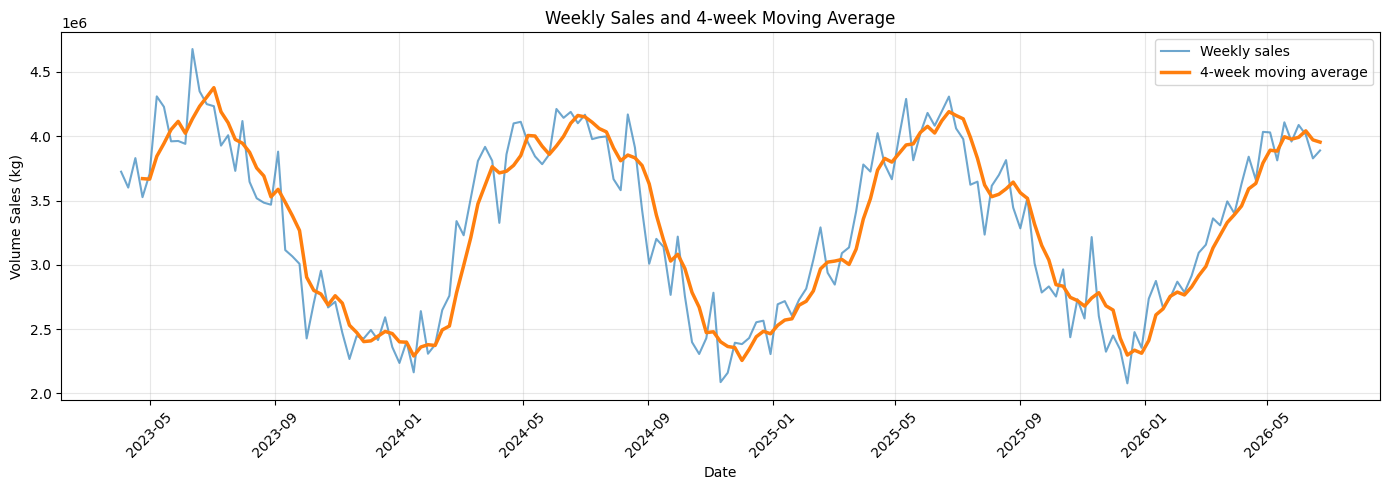

In [66]:
# Rolling average uses historical observations only
mmm_df["Volume_Sales_MA4"] = mmm_df[TARGET].rolling(window=4, min_periods=4).mean()
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(mmm_df["Date"], mmm_df[TARGET], alpha=0.65, label="Weekly sales")
ax.plot(mmm_df["Date"], mmm_df["Volume_Sales_MA4"], linewidth=2.5, label="4-week moving average")
ax.set(title="Weekly Sales and 4-week Moving Average", xlabel="Date", ylabel="Volume Sales (kg)")
ax.tick_params(axis="x", rotation=45)
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


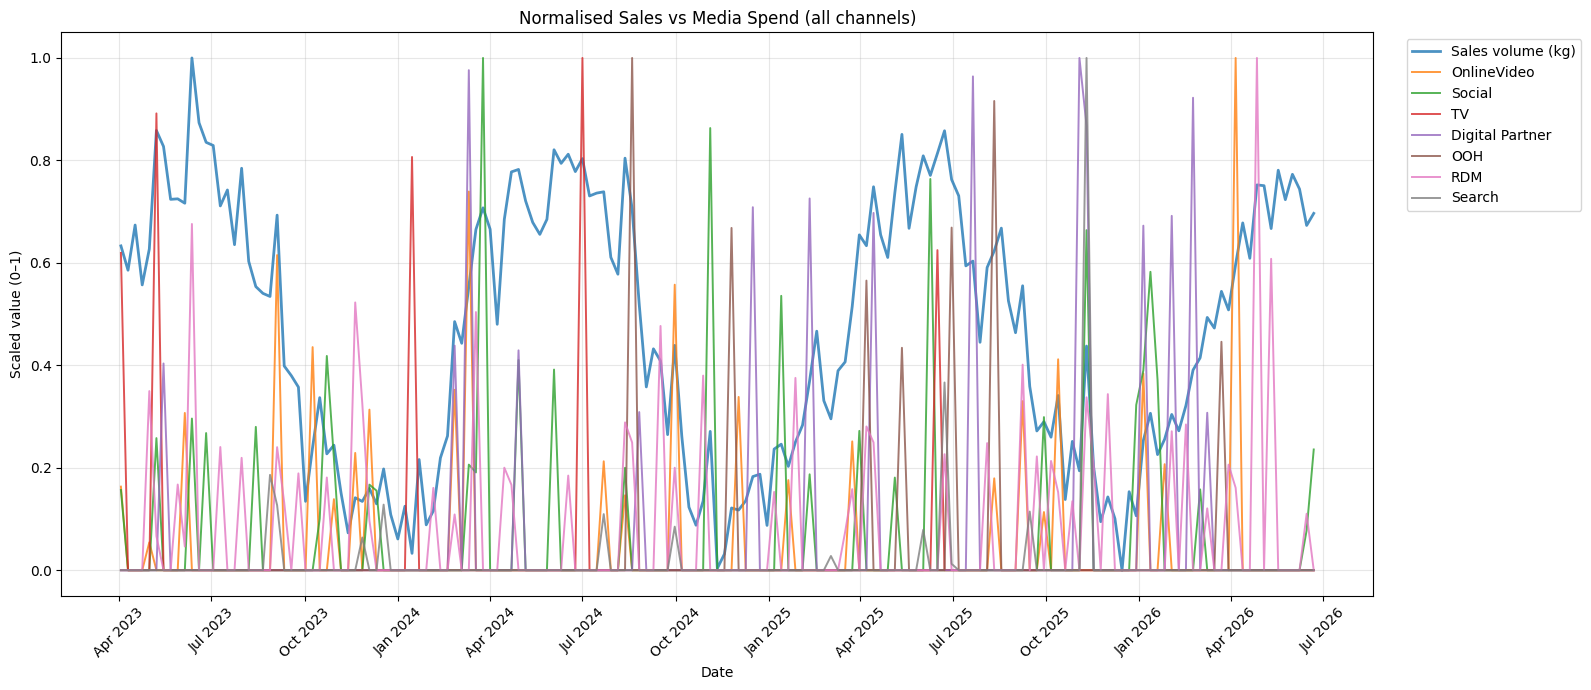

In [67]:
# Normalise sales and all seven media spends separately for visual comparison.
# These EDA-only scalings are NOT used as training-set transformations.
from sklearn.preprocessing import MinMaxScaler
columns_to_scale = [TARGET] + MEDIA_COLS
plot_df = mmm_df[[DATE_COL] + columns_to_scale].copy()
plot_df[columns_to_scale] = MinMaxScaler().fit_transform(plot_df[columns_to_scale])
fig, ax = plt.subplots(figsize=(16, 7))
for col in columns_to_scale:
    label = "Sales volume (kg)" if col == TARGET else media_labels[col]
    ax.plot(plot_df[DATE_COL], plot_df[col], label=label, alpha=0.8,
            linewidth=2 if col == TARGET else 1.4)
ax.set(title="Normalised Sales vs Media Spend (all channels)", xlabel="Date", ylabel="Scaled value (0–1)")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.tick_params(axis="x", rotation=45)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


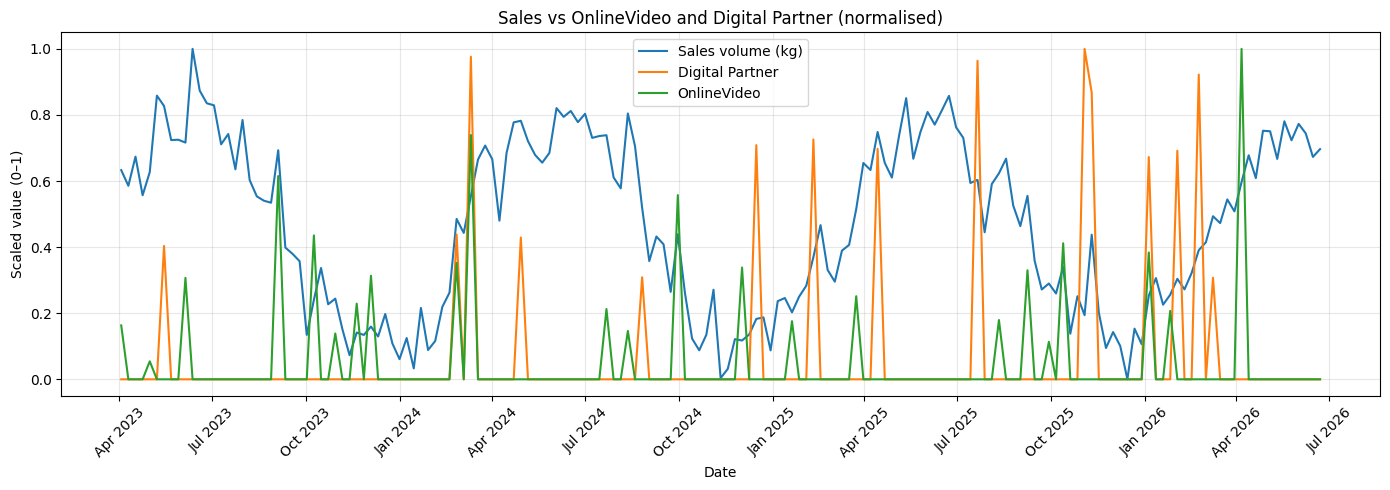

In [68]:
from sklearn.preprocessing import MinMaxScaler
focus_cols = [TARGET, "Md_Digital_Partner_Spends", "Md_OnlineVideo_Spends"]
plot_df = mmm_df[[DATE_COL] + focus_cols].copy()
plot_df[focus_cols] = MinMaxScaler().fit_transform(plot_df[focus_cols])
fig, ax = plt.subplots(figsize=(14, 5))
for col in focus_cols:
    label = "Sales volume (kg)" if col == TARGET else media_labels[col]
    ax.plot(plot_df[DATE_COL], plot_df[col], label=label)
ax.set(title="Sales vs OnlineVideo and Digital Partner (normalised)",
       xlabel="Date", ylabel="Scaled value (0–1)")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.tick_params(axis="x", rotation=45)
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


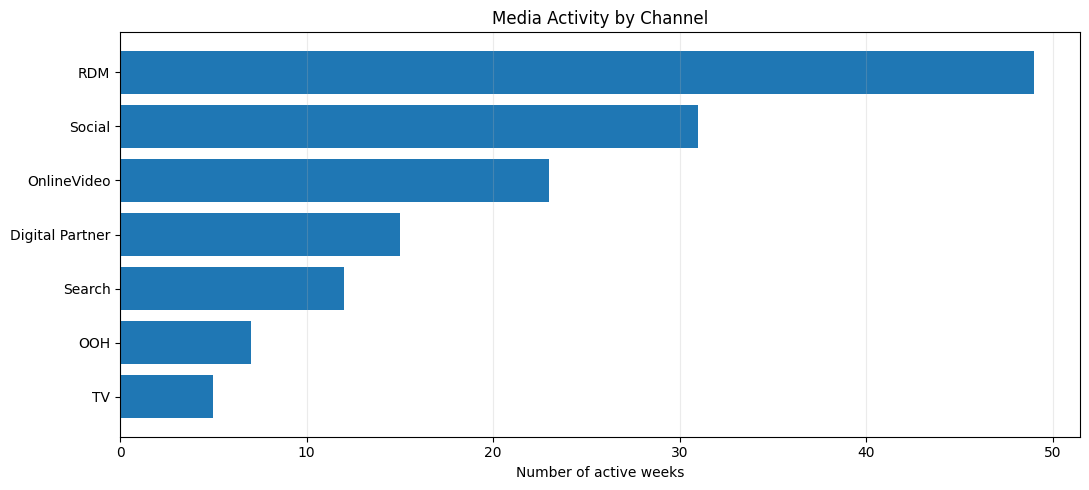

,Active weeks
TV,5
OOH,7
Search,12
Digital Partner,15
OnlineVideo,23
Social,31
RDM,49


In [69]:
# Number of active weeks per media channel, where spend > 0
active_weeks = pd.Series({media_labels[c]: int(mmm_df[c].gt(0).sum()) for c in MEDIA_COLS})
active_weeks = active_weeks.sort_values()
fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(active_weeks.index, active_weeks.values)
ax.set(title="Media Activity by Channel", xlabel="Number of active weeks", ylabel="")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()
display(active_weeks.to_frame("Active weeks"))


## 3. Build potential baseline modelling features
This exploratory section selects a nonlinear temperature threshold using **time-series cross-validation on the training period only**. The holdout portion remains untouched. It does **not** fit the full Bayesian MMM, and the suggested features can differ from a separately specified Bayesian notebook.


In [70]:
model_df = mmm_df.copy()
print("Rows:", len(model_df))
print("Columns available for feature engineering:", len(model_df.columns))


Rows: 169
Columns available for feature engineering: 24


Total observations: 169
Training observations: 135
Test observations: 34


,threshold_C,CV_RMSE,Best_Ridge_Alpha
0,17°C,"252,382",0.0412
1,18°C,"254,749",0.2154
2,15°C,"254,936",0.1425
3,19°C,"256,737",0.3257
4,20°C,"257,130",0.4924
5,14°C,"259,006",0.3257
6,13°C,"262,603",0.4924
7,16°C,"271,627",8.8862
8,12°C,"271,683",0.7444
9,11°C,"278,860",0.7444



Selected heat threshold from TRAINING CV: 17 °C
Selected heat feature: Heat_Above_17C
Best Ridge alpha: 0.0412


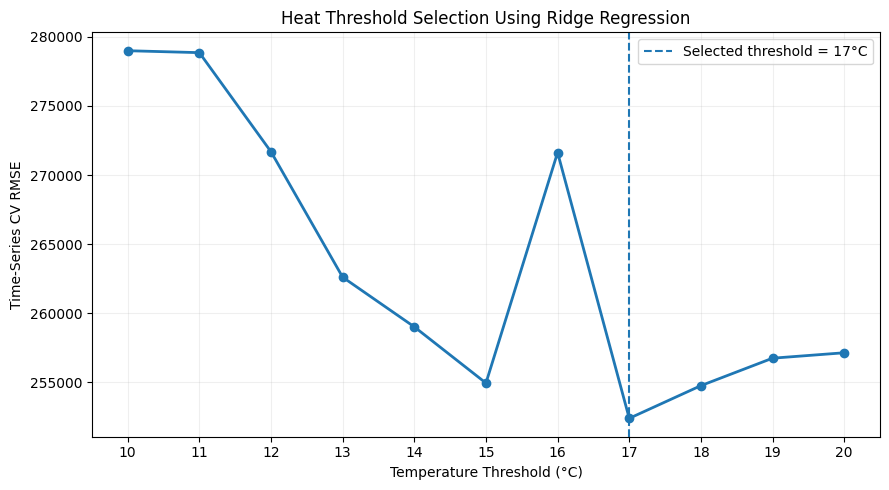


Final baseline variables:
- Trend
- sin52
- cos52
- weather_average_temp
- Heat_Above_17C
- weather_rainfall
- Log_Relative_Price_Deviation
- Promotion_Discount_Depth
- ACV_Weighted_Distribution_wtd
- Promotion_ACV_Weighted_Distribution_wtd


In [71]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit




# Create trend

model_df["Trend"] = np.arange(
    len(model_df),
    dtype=float
)


# CREATE ANNUAL SEASONALITY
#    Weekly data -> approximately 52 weeks/year


model_df["sin52"] = np.sin(
    2 * np.pi
    * model_df["Trend"]
    / 52.0
)

model_df["cos52"] = np.cos(
    2 * np.pi
    * model_df["Trend"]
    / 52.0
)



# CREATE PROMOTION DISCOUNT DEPTH

model_df["Promotion_Discount_Depth"] = (
    1
    - model_df["Promotion_Avg_Price"]
    / model_df["Base_Avg_Price"]
).clip(lower=0)


# CREATE COMPETITOR PRICE INDEX


competitor_price_cols = [
    "Comp_Brand1_Base_Avg_Price",
    "Comp_Brand2_Base_Avg_Price",
]


model_df["Competitor_Base_Price_Index"] = (
    model_df[
        competitor_price_cols
    ]
    .mean(axis=1)
)


# CREATE LOG RELATIVE PRICE


model_df["Log_Relative_Price"] = np.log(
    model_df["Base_Avg_Price"]
    /
    model_df["Competitor_Base_Price_Index"]
)


#  CHRONOLOGICAL 80/20 SPLIT


SPLIT = int(
    len(model_df) * 0.80
)


train_df = (
    model_df
    .iloc[:SPLIT]
    .copy()
)

test_df = (
    model_df
    .iloc[SPLIT:]
    .copy()
)


print(
    "Total observations:",
    len(model_df)
)

print(
    "Training observations:",
    len(train_df)
)

print(
    "Test observations:",
    len(test_df)
)



# DETREND RELATIVE PRICE
#    FIT USING TRAINING DATA ONLY

price_trend = LinearRegression().fit(
    train_df[["Trend"]],
    train_df["Log_Relative_Price"]
)


model_df[
    "Log_Relative_Price_Deviation"
] = (
    model_df["Log_Relative_Price"]
    -
    price_trend.predict(
        model_df[["Trend"]]
    )
)


# Refresh train/test data after feature creation

train_df = (
    model_df
    .iloc[:SPLIT]
    .copy()
)

test_df = (
    model_df
    .iloc[SPLIT:]
    .copy()
)



# FEATURES USED FOR HEAT-THRESHOLD SEARCH


base_without_heat = [
    "Trend",
    "sin52",
    "cos52",
    "weather_average_temp",
    "weather_rainfall",
    "Log_Relative_Price_Deviation",
    "Promotion_Discount_Depth",
    "ACV_Weighted_Distribution_wtd",
    "Promotion_ACV_Weighted_Distribution_wtd",
]


#  SEARCH HEAT THRESHOLD
#     USING RIDGE + TRAINING DATA ONLY


heat_search = []


for threshold in range(10, 21):


    col = (
        f"Heat_Above_{threshold}C"
    )


    model_df[col] = (
        model_df[
            "weather_average_temp"
        ]
        - threshold
    ).clip(lower=0)


    features = (
        base_without_heat
        + [col]
    )




    X = (
        model_df
        .iloc[:SPLIT][features]
        .values
    )

    y = (
        model_df
        .iloc[:SPLIT][TARGET]
        .values
    )



    # Ridge Regression Pipeline
    pipe = Pipeline([

        (
            "scale",
            StandardScaler()
        ),

        (
            "ridge",
            Ridge()
        )

    ])


    grid = GridSearchCV(

        estimator=pipe,

        param_grid={
            "ridge__alpha":
                np.logspace(
                    -3,
                    4,
                    40
                )
        },

        scoring=
            "neg_root_mean_squared_error",

        cv=
            TimeSeriesSplit(
                n_splits=5
            ),

        n_jobs=1
    )


    grid.fit(
        X,
        y
    )



    # Store CV performance


    heat_search.append({

        "threshold_C":
            threshold,

        "CV_RMSE":
            -grid.best_score_,

        "Best_Ridge_Alpha":
            grid.best_params_[
                "ridge__alpha"
            ]
    })



#THRESHOLD RESULTS


heat_search = (
    pd.DataFrame(
        heat_search
    )
    .sort_values(
        "CV_RMSE",
        ascending=True
    )
    .reset_index(drop=True)
)


display(
    heat_search.style.format({

        "threshold_C":
            "{:.0f}°C",

        "CV_RMSE":
            "{:,.0f}",

        "Best_Ridge_Alpha":
            "{:.4f}"
    })
)


#  SELECT BEST HEAT THRESHOLD


HEAT_THRESHOLD = int(
    heat_search.loc[
        0,
        "threshold_C"
    ]
)


HEAT_COL = (
    f"Heat_Above_"
    f"{HEAT_THRESHOLD}C"
)


BEST_HEAT_ALPHA = float(
    heat_search.loc[
        0,
        "Best_Ridge_Alpha"
    ]
)


print(
    "\nSelected heat threshold from TRAINING CV:",
    HEAT_THRESHOLD,
    "°C"
)

print(
    "Selected heat feature:",
    HEAT_COL
)

print(
    "Best Ridge alpha:",
    round(
        BEST_HEAT_ALPHA,
        4
    )
)



plot_df = (
    heat_search
    .sort_values(
        "threshold_C"
    )
)


plt.figure(
    figsize=(9, 5)
)


plt.plot(
    plot_df[
        "threshold_C"
    ],
    plot_df[
        "CV_RMSE"
    ],
    marker="o",
    linewidth=2
)


plt.axvline(
    HEAT_THRESHOLD,
    linestyle="--",
    label=(
        f"Selected threshold = "
        f"{HEAT_THRESHOLD}°C"
    )
)


plt.xlabel(
    "Temperature Threshold (°C)"
)

plt.ylabel(
    "Time-Series CV RMSE"
)

plt.title(
    "Heat Threshold Selection Using Ridge Regression"
)

plt.xticks(
    range(10, 21)
)

plt.grid(
    alpha=0.2
)

plt.legend()

plt.tight_layout()

plt.show()


# FINAL BASE FEATURES


BASE_FEATURES = [
    "Trend",
    "sin52",
    "cos52",
    "weather_average_temp",
    HEAT_COL,
    "weather_rainfall",
    "Log_Relative_Price_Deviation",
    "Promotion_Discount_Depth",
    "ACV_Weighted_Distribution_wtd",
    "Promotion_ACV_Weighted_Distribution_wtd",
]


print(
    "\nFinal baseline variables:"
)

for feature in BASE_FEATURES:
    print("-", feature)